# 🍄 Taller de Clustering — Parte 1: Setas

Notebook de trabajo: solo contiene las fases ya vistas (ver [`learn_roadmap.md`](learn_roadmap.md)).

## ✅ Fase 01 · Comprensión del problema y de los datos — ya vista

> **Resumen fase 01:** 8124 setas × 23 columnas, **todas categóricas** (letras). Hay etiqueta (`class`), pero solo para validar. No hay nulos *aparentes*.

▶️ **Ejecuta primero la celda plegada de abajo** (o usa *Run All*): crea `df`, `X`, `y`… que necesita la fase actual. Pulsa `…` para ver su código.

In [1]:
%matplotlib inline
# Hace que los gráficos aparezcan dentro del notebook
import warnings
warnings.filterwarnings("ignore")  # oculta avisos para que la salida quede limpia

import pandas as pd              # DataFrame: la "hoja de cálculo" con la que trabajamos
import numpy as np               # cálculo numérico
import seaborn as sns            # gráficos estadísticos con poco código
import matplotlib.pyplot as plt  # base de todos los gráficos

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42  # semilla fija: así los resultados se pueden repetir

df = pd.read_csv("docs/workshop/data/mushrooms.csv")  # la tabla con todas las setas
print("Filas x columnas:", df.shape)
df.head()  # las 5 primeras filas

# Con texto, describe() da: count (filas), unique (valores distintos),
# top (el más repetido) y freq (cuántas veces sale).
df.describe()

# Tipo de cada columna: todas salen 'str' (texto; en pandas antiguos sale 'object').
# Cada letra es un código, p. ej. en 'class': e = comestible, p = venenosa.
df.info()

# ¿Cuántas setas de cada clase? (solo para conocer los datos, no para agrupar)
df["class"].value_counts()

# Contar nulos por columna. Sale todo 0... pero ojo: los valores desconocidos
# pueden estar escritos como '?' (lo veremos en la fase 02).
df.isnull().sum()

Filas x columnas: (8124, 23)
<class 'pandas.DataFrame'>
RangeIndex: 8124 entries, 0 to 8123
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   class                     8124 non-null   str  
 1   cap-shape                 8124 non-null   str  
 2   cap-surface               8124 non-null   str  
 3   cap-color                 8124 non-null   str  
 4   bruises                   8124 non-null   str  
 5   odor                      8124 non-null   str  
 6   gill-attachment           8124 non-null   str  
 7   gill-spacing              8124 non-null   str  
 8   gill-size                 8124 non-null   str  
 9   gill-color                8124 non-null   str  
 10  stalk-shape               8124 non-null   str  
 11  stalk-root                8124 non-null   str  
 12  stalk-surface-above-ring  8124 non-null   str  
 13  stalk-surface-below-ring  8124 non-null   str  
 14  stalk-color-above-ring

class                       0
cap-shape                   0
cap-surface                 0
cap-color                   0
bruises                     0
odor                        0
gill-attachment             0
gill-spacing                0
gill-size                   0
gill-color                  0
stalk-shape                 0
stalk-root                  0
stalk-surface-above-ring    0
stalk-surface-below-ring    0
stalk-color-above-ring      0
stalk-color-below-ring      0
veil-type                   0
veil-color                  0
ring-number                 0
ring-type                   0
spore-print-color           0
population                  0
habitat                     0
dtype: int64

## ✅ Fase 02 · Preparación de los datos — ya vista

> **Resumen fase 02:** `'?'` → moda en `stalk-root`, fuera `veil-type`, etiqueta separada en `y` y **One-Hot** para pasar de 22 columnas de letras a columnas 0/1.

▶️ **Ejecuta primero la celda plegada de abajo** (o usa *Run All*): crea `df`, `X`, `y`… que necesita la fase actual. Pulsa `…` para ver su código.

In [2]:
n_values = pd.DataFrame({
    "feature": df.columns,                                  # nombre de cada columna
    "n_values": [df[col].nunique() for col in df.columns],  # cuántos valores distintos tiene
})
n_values.sort_values("n_values").head()  # de menos a más: lo raro sale arriba

# Imprimimos los valores distintos de cada columna, ordenados.
# Buscamos a ojo algo que no sea una letra-código: '?', '-', 'NA', ''...
for col in df.columns:
    print(f"{col:26} {sorted(df[col].unique())}")

# Lo confirmamos contando: ¿cuántos '?' hay en cada columna? Nos quedamos con las que tengan alguno.
interrogantes = (df == "?").sum()
interrogantes[interrogantes > 0]

# Ya sabemos dónde mirar: ¿cuánto pesa el '?' dentro de 'stalk-root'?
df["stalk-root"].value_counts()

# La moda es el valor más repetido. La calculamos SIN contar los '?'.
moda = df.loc[df["stalk-root"] != "?", "stalk-root"].mode()[0]
print("Moda de stalk-root:", moda)

df["stalk-root"] = df["stalk-root"].replace("?", moda)  # cambiamos cada '?' por la moda
df["stalk-root"].value_counts()

# Columnas con un solo valor: son iguales en todas las setas, no ayudan a distinguir nada
constantes = [col for col in df.columns if df[col].nunique() == 1]
print("Eliminamos:", constantes)
df = df.drop(columns=constantes)
df.shape

y = (df["class"] == "p").astype(int)  # 1 = venenosa, 0 = comestible (solo para validar)
X = df.drop(columns="class")          # las características de la seta
X.shape, y.value_counts().to_dict()

X = pd.get_dummies(X, dtype=int)  # una columna 0/1 por cada valor posible
print("Columnas tras One-Hot:", X.shape[1])
X.iloc[:3, :8]  # vistazo a las primeras columnas

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=RANDOM_STATE)
X_train.shape, X_test.shape

class                      ['e', 'p']
cap-shape                  ['b', 'c', 'f', 'k', 's', 'x']
cap-surface                ['f', 'g', 's', 'y']
cap-color                  ['b', 'c', 'e', 'g', 'n', 'p', 'r', 'u', 'w', 'y']
bruises                    ['f', 't']
odor                       ['a', 'c', 'f', 'l', 'm', 'n', 'p', 's', 'y']
gill-attachment            ['a', 'f']
gill-spacing               ['c', 'w']
gill-size                  ['b', 'n']
gill-color                 ['b', 'e', 'g', 'h', 'k', 'n', 'o', 'p', 'r', 'u', 'w', 'y']
stalk-shape                ['e', 't']
stalk-root                 ['?', 'b', 'c', 'e', 'r']
stalk-surface-above-ring   ['f', 'k', 's', 'y']
stalk-surface-below-ring   ['f', 'k', 's', 'y']
stalk-color-above-ring     ['b', 'c', 'e', 'g', 'n', 'o', 'p', 'w', 'y']
stalk-color-below-ring     ['b', 'c', 'e', 'g', 'n', 'o', 'p', 'w', 'y']
veil-type                  ['p']
veil-color                 ['n', 'o', 'w', 'y']
ring-number                ['n', 'o', 't']
ring-typ

((5443, 115), (2681, 115))

## ✅ Fase 03 · Exploración y reducción de dimensionalidad — ya vista

> **Resumen fase 03:** con **PCA** se ven zonas separadas; **Random Forest** acierta ≈ 100 % (los datos tienen mucha información) y **~10 componentes PCA** bastan para mantenerlo. **t-SNE** muestra grupos más compactos, pero solo sirve para visualizar.

▶️ **Ejecuta primero la celda plegada de abajo** (o usa *Run All*): crea `df`, `X`, `y`… que necesita la fase actual. Pulsa `…` para ver su código.

Varianza explicada por PC1 y PC2: [0.169 0.127] -> total 0.296


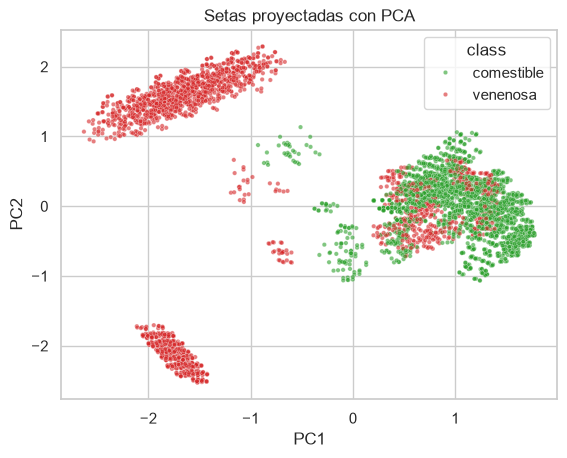

Columnas que participan en PC1: 115 de 115
Para guardar el 95 % de la varianza hacen falta 40 de 115 columnas


Accuracy con las 115 columnas: 1.000
Modelo tonto: 0.514  vs  Random Forest: 1.000


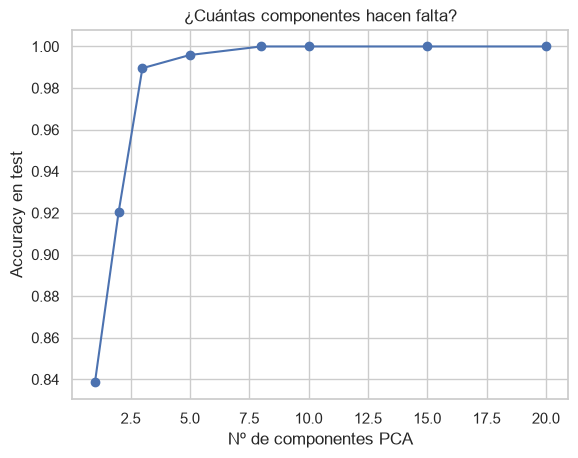

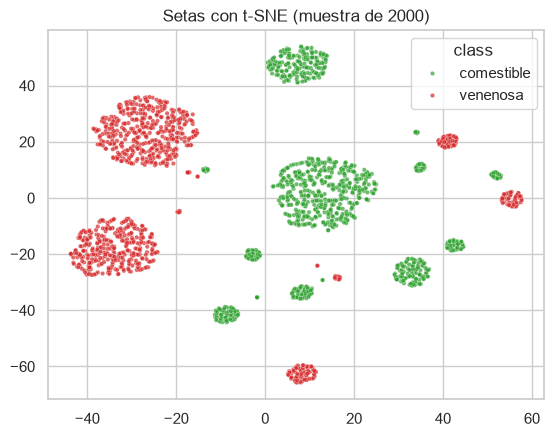

In [3]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_train)  # cada seta pasa a ser un punto (PC1, PC2)
print("Varianza explicada por PC1 y PC2:", pca.explained_variance_ratio_.round(3),
      "-> total", pca.explained_variance_ratio_.sum().round(3))

# Coloreamos con la etiqueta SOLO para mirar: PCA no la ha usado
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=y_train.map({0: "comestible", 1: "venenosa"}),
                hue_order=["comestible", "venenosa"], palette={"comestible": "tab:green", "venenosa": "tab:red"},
                s=10, alpha=0.6)
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.title("Setas proyectadas con PCA")
plt.show()

# ¿Qué hay DENTRO de PC1? Sus pesos: cuánto aporta cada una de las 115 columnas
pesos_pc1 = pd.Series(pca.components_[0], index=X_train.columns)
print("Columnas que participan en PC1:", (pesos_pc1 != 0).sum(), "de", X_train.shape[1])
pesos_pc1.reindex(pesos_pc1.abs().sort_values(ascending=False).index).head(5).round(2)

# 📖 Idea del primer libro: ¿cuántas componentes guardan el 95 % de la varianza en NUESTRAS setas?
pca95 = PCA(n_components=0.95, random_state=RANDOM_STATE).fit(X_train)  # un número entre 0 y 1 = % de varianza
print(f"Para guardar el 95 % de la varianza hacen falta {pca95.n_components_} de {X_train.shape[1]} columnas")

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

rf = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE)  # 100 árboles que votan
rf.fit(X_train, y_train)                    # aprende con train
acc = accuracy_score(y_test, rf.predict(X_test))  # examen con test (datos que no ha visto)
print(f"Accuracy con las {X_train.shape[1]} columnas: {acc:.3f}")

# 📖 Idea de los libros: comparar con un modelo 'tonto' que siempre dice la clase más frecuente
from sklearn.dummy import DummyClassifier

dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
print(f"Modelo tonto: {accuracy_score(y_test, dummy.predict(X_test)):.3f}  vs  Random Forest: {acc:.3f}")

n_features = [1, 2, 3, 5, 8, 10, 15, 20]  # valores de n a probar
scores = []

for n in n_features:
    pca_n = PCA(n_components=n, random_state=RANDOM_STATE).fit(X_train)  # PCA aprende SOLO con train
    rf_n = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE)
    rf_n.fit(pca_n.transform(X_train), y_train)
    scores.append(accuracy_score(y_test, rf_n.predict(pca_n.transform(X_test))))

plt.plot(n_features, scores, marker="o")
plt.xlabel("Nº de componentes PCA"); plt.ylabel("Accuracy en test")
plt.title("¿Cuántas componentes hacen falta?")
plt.show()
dict(zip(n_features, [round(s, 3) for s in scores]))

from sklearn.manifold import TSNE

muestra = X_train.sample(2000, random_state=RANDOM_STATE)  # t-SNE es lento: 2000 setas bastan
X_tsne = TSNE(n_components=2, perplexity=30, random_state=RANDOM_STATE).fit_transform(muestra)

sns.scatterplot(x=X_tsne[:, 0], y=X_tsne[:, 1],
                hue=y_train.loc[muestra.index].map({0: "comestible", 1: "venenosa"}), hue_order=["comestible", "venenosa"], palette={"comestible": "tab:green", "venenosa": "tab:red"},
                s=10, alpha=0.7)
plt.title("Setas con t-SNE (muestra de 2000)")
plt.show()

## Fase 04 · Modelado: buscar grupos sin mirar la etiqueta

**Objetivo:** probar **4 algoritmos de clustering** (K-Means, Aglomerativo, GMM y DBSCAN) y ver qué grupos encuentran **solos**. La etiqueta `y` **no se usa** para entrenar.

### Preparar los datos: PCA a 10 componentes

En la fase 03 vimos que con **~10 componentes** ya está casi toda la información útil. Trabajamos sobre esa versión reducida (`X_red`): **quita ruido y hace los algoritmos más rápidos**.

Usamos **todo `X`** (no solo train): en clustering no hay que predecir nada nuevo, queremos agrupar todas las setas.

In [4]:
# Reducimos las 115 columnas one-hot a 10 componentes
X_red = PCA(n_components=10, random_state=RANDOM_STATE).fit_transform(X)
X_red.shape

(8124, 10)

### K-Means: grupos alrededor de un centro

**Qué es:** eliges **k** (cuántos grupos). El algoritmo pone k centros, mete cada seta en el **centro más cercano**, mueve cada centro al **promedio** de su grupo y repite hasta que nada cambia.

- *Analogía:* k repartidores en una ciudad; cada casa va al repartidor más cercano.
- **Problema:** hay que decirle k. Para elegirlo usamos dos pistas:
  - **Codo (inercia):** cuánto se alejan los puntos de su centro. **Siempre baja** al subir k; buscamos dónde la curva **se dobla**.
  - **Silueta:** de −1 a 1, **cuánto mejor está cada punto en su grupo que en el vecino**. Más alta = mejor.

![K-Means](assets/taller/f04-kmeans.png)

![Método del codo](assets/taller/f04-codo.png)

![Silueta](assets/taller/f04-silueta.png)

*Fuente: diapositivas del bootcamp «Aprendizaje No Supervisado» (FactoriaF5).*

> 📖 **En los libros**
>
> - **Primer libro:** 5 grupos inventados (*blobs*). El **codo** sale en **k = 4** y la **silueta** más alta también (0,689)… pero la respuesta buena es **k = 5**: lo descubre mirando el **diagrama de silueta** (con k = 4 un grupo es enorme). **Las métricas son pistas**, como nos pasa con las setas.
> - **Segundo libro:** dónde organizar quedadas para **20 usuarios** según su barrio. El error total baja de **>15.000** (k = 1) a **4.400** (k = 2) y a **1.200** (k = 3); después casi no baja → **codo claro en k = 3**. Avisa: si k = nº de puntos, el error es 0, por eso no se elige el k con menos error.

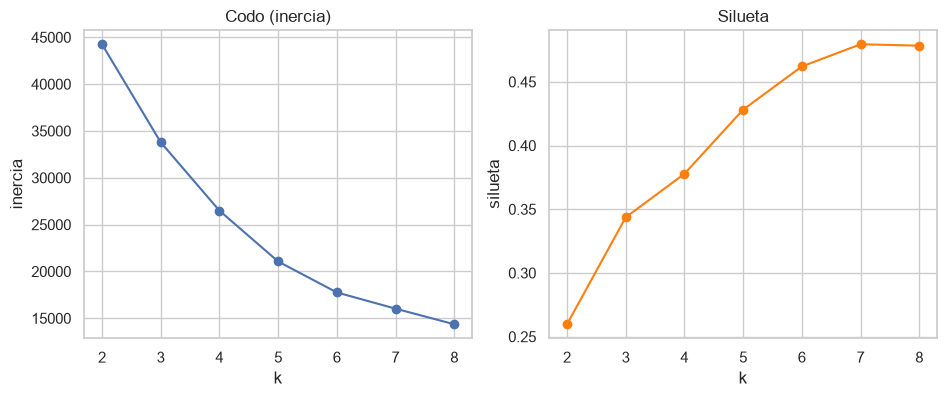

,k,inercia,silueta
0,2,44251.650,0.260
1,3,33784.320,0.344
2,4,26490.413,0.378
3,5,21060.524,0.428
4,6,17755.768,0.462
5,7,16023.219,0.479
6,8,14357.278,0.478


In [5]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

k_values = range(2, 9)
inercias, siluetas = [], []
for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_red)
    inercias.append(km.inertia_)                      # codo: distancia total a los centros
    siluetas.append(silhouette_score(X_red, km.labels_,
                                     sample_size=3000, random_state=RANDOM_STATE))  # muestra: más rápido

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(k_values, inercias, "o-"); ax[0].set(title="Codo (inercia)", xlabel="k", ylabel="inercia")
ax[1].plot(k_values, siluetas, "o-", color="tab:orange"); ax[1].set(title="Silueta", xlabel="k", ylabel="silueta")
plt.show()
pd.DataFrame({"k": k_values, "inercia": inercias, "silueta": siluetas}).round(3)

**Lectura honesta:** aquí el codo **no es claro** y la silueta **sigue subiendo** con k (hay muchos subtipos de setas). Las métricas son **pistas, no la respuesta**: la decide también **la pregunta de negocio**. Nuestra pregunta es *«¿se separan solas en 2 grupos (comestible / venenosa)?»*, así que probamos **k = 2**.

In [6]:
kmeans = KMeans(n_clusters=2, n_init=10, random_state=RANDOM_STATE).fit(X_red)
clusters_km = kmeans.labels_

# Cuántas setas hay en cada cluster
print(pd.Series(clusters_km).value_counts().sort_index())

# Solo para MIRAR (no para entrenar): ¿qué hay dentro de cada cluster?
pd.crosstab(clusters_km, y.map({0: "comestible", 1: "venenosa"}),
            rownames=["cluster"], colnames=["etiqueta real"])

0    4969
1    3155
Name: count, dtype: int64


etiqueta real,comestible,venenosa
cluster,,
0,4153,816
1,55,3100


### Aglomerativo (jerárquico): un árbol de grupos

**Qué es:** cada seta empieza **sola**; en cada paso se **unen los dos grupos más cercanos**, hasta que todo es un grupo. El resultado es un **árbol (dendrograma)**.

- *Analogía:* un árbol genealógico: personas → parejas → familias → clan.
- **No hay que elegir k al principio:** se elige después, **cortando el árbol** a una altura. Cuanto más alta la unión, más distintos eran los grupos.
- Con `method="ward"` une los grupos que menos aumentan la dispersión (parecido a K-Means).

![Cómo leer un dendrograma](assets/taller/f04-dendrograma.png)

*Fuente: diapositivas del bootcamp «Aprendizaje No Supervisado» (FactoriaF5).*

> 📖 **En los libros**
>
> - **Segundo libro:** los mismos **20 usuarios**: el árbol hace **19 uniones** hasta tener un solo grupo. **Cortar arriba** da **2 grupos (6 y 14 usuarios)**; cortar un poco más abajo, 3.
> - **Primer libro:** visitantes de un blog: un grupo de **40 % adolescentes** (después de clase) y otro de **20 % adultos** (fines de semana), que el jerárquico puede **subdividir** en grupos más pequeños.

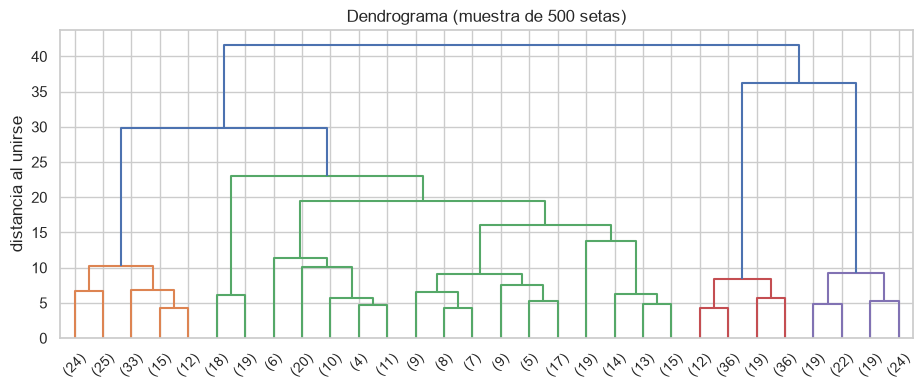

0    3024
1    5100
Name: count, dtype: int64

In [7]:
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.cluster import AgglomerativeClustering

# El dendrograma con 8124 setas no se lee: usamos una muestra de 500
rng = np.random.default_rng(RANDOM_STATE)
muestra = X_red[rng.choice(len(X_red), size=500, replace=False)]
arbol = linkage(muestra, method="ward")

plt.figure(figsize=(11, 4))
dendrogram(arbol, truncate_mode="lastp", p=30)   # enseña solo las 30 últimas uniones
plt.title("Dendrograma (muestra de 500 setas)"); plt.ylabel("distancia al unirse")
plt.show()

# Cortamos el árbol en 2 grupos sobre TODOS los datos
clusters_ag = AgglomerativeClustering(n_clusters=2, linkage="ward").fit_predict(X_red)
pd.Series(clusters_ag).value_counts().sort_index()

### GMM (mezcla de gaussianas): grupos con probabilidad

**Qué es:** supone que cada grupo es una **campana (gaussiana)** que puede ser **alargada o inclinada**, no solo redonda como en K-Means.

- **Diferencia clave:** K-Means da a cada seta **un solo grupo**; GMM le da **una probabilidad por grupo** (p. ej. 70 % grupo 0, 30 % grupo 1). Es una **asignación probabilística**.
- *Analogía:* las estaturas de un grupo: muchas cerca de la media, pocas en los extremos.

![GMM](assets/taller/f04-gmm.png)

*Fuente: diapositivas del bootcamp «Aprendizaje No Supervisado» (FactoriaF5).*

> 📖 **En los libros**
>
> - **Primer libro:** 1.250 puntos en **3 elipses** (500 / 500 / 250). GMM descubre sus pesos (≈ 0,40 / 0,21 / 0,39) y para cada punto da probabilidades como **97,7 %** de un grupo. Además sirve para **anomalías**: marca el **2 %** de puntos en las zonas de menos densidad. Con las flores **Iris** solo falla **5 de 150**.
> - **Segundo libro:** no trata GMM (solo K-Means y jerárquico).

In [8]:
from sklearn.mixture import GaussianMixture

gmm = GaussianMixture(n_components=2, random_state=RANDOM_STATE).fit(X_red)
clusters_gmm = gmm.predict(X_red)          # el grupo más probable
probs = gmm.predict_proba(X_red)            # probabilidad de cada grupo

print(pd.Series(clusters_gmm).value_counts().sort_index())
print("Setas con duda (ningún grupo > 90 %):", (probs.max(axis=1) < 0.9).sum())
pd.DataFrame(probs[:5], columns=["P(grupo 0)", "P(grupo 1)"]).round(3)

0    5073
1    3051
Name: count, dtype: int64
Setas con duda (ningún grupo > 90 %): 34


,P(grupo 0),P(grupo 1)
0,1.0,0.0
1,1.0,0.0
2,1.0,0.0
3,1.0,0.0
4,1.0,0.0


### DBSCAN: grupos por densidad (y la distancia importa)

**Qué es:** un grupo es una **zona con muchos puntos juntos**. No hay que elegir k. Tiene **2 parámetros**:

- **`eps`:** la distancia máxima para considerar a dos puntos **vecinos** (el radio).
- **`min_samples`:** cuántos vecinos hacen falta para que un punto sea **núcleo** de un grupo.
- Quien queda lejos de todos es **ruido** (etiqueta **−1**).

![DBSCAN](assets/taller/f04-dbscan.png)

**La distancia importa:** nuestras setas son **0/1**. La distancia **euclídea** mide «cuánto se diferencian los números»; la de **Jaccard** mide «de las características que tiene alguna de las dos, **cuántas comparten**». Para datos 0/1, Jaccard tiene más sentido.

![One-hot y Jaccard](assets/taller/f04-jaccard.png)

*Fuente: diapositivas del bootcamp «Aprendizaje No Supervisado» (FactoriaF5).*

> 📖 **En los libros**
>
> - **Primer libro:** dos **lunas** de 1.000 puntos. Con **`eps = 0.05`** salen **7 grupos** y mucho ruido; con **`eps = 0.20`**, las **2 lunas** casi sin ruido. **Un pequeño cambio de `eps` lo cambia todo**, igual que con nuestras setas.
> - **Ninguno de los dos libros** usa Jaccard: el segundo, para vectores 0/1 (intereses de usuarios), usa la similitud **coseno**. La idea es la misma: **con datos 0/1, la distancia euclídea no es la mejor**.

No sabemos qué `eps` usar, así que **probamos varios** y contamos cuántos grupos salen.

In [9]:
from sklearn.cluster import DBSCAN

def resumen_dbscan(labels):
    n_grupos = len(set(labels)) - (1 if -1 in labels else 0)   # el -1 (ruido) no es un grupo
    return n_grupos, (labels == -1).sum()

# 1) Distancia EUCLÍDEA sobre X_red
for eps in [0.5, 1, 1.5, 2, 3]:
    labels = DBSCAN(eps=eps, min_samples=10).fit_predict(X_red)
    print(f"euclídea eps={eps:<4} -> grupos: %3d  ruido: %d" % resumen_dbscan(labels))

euclídea eps=0.5  -> grupos: 130  ruido: 690


euclídea eps=1    -> grupos:  36  ruido: 24


euclídea eps=1.5  -> grupos:   6  ruido: 0


euclídea eps=2    -> grupos:   4  ruido: 0


euclídea eps=3    -> grupos:   1  ruido: 0


In [10]:
# 2) Distancia de JACCARD sobre el one-hot original (True/False)
X_bin = X.values.astype(bool)
for eps in [0.2, 0.3, 0.4, 0.5]:
    labels = DBSCAN(eps=eps, min_samples=10, metric="jaccard").fit_predict(X_bin)
    print(f"jaccard  eps={eps:<4} -> grupos: %3d  ruido: %d" % resumen_dbscan(labels))

clusters_db = DBSCAN(eps=0.4, min_samples=10, metric="jaccard").fit_predict(X_bin)  # lo guardamos para la fase 05

jaccard  eps=0.2  -> grupos:  19  ruido: 16


jaccard  eps=0.3  -> grupos:  14  ruido: 16


jaccard  eps=0.4  -> grupos:   5  ruido: 8


jaccard  eps=0.5  -> grupos:   3  ruido: 5


**Lectura:** con **euclídea**, `eps` pequeño **rompe** las setas en decenas de trocitos (130 grupos y 690 de ruido) y `eps` grande lo junta **todo en 1 grupo**. Con **Jaccard** el número de grupos baja **poco a poco** (19 → 14 → 5 → 3) y casi no hay ruido. Nos quedamos con `eps = 0.4` (5 grupos).

⚠️ Ninguno da exactamente 2 grupos: DBSCAN no busca «comestible / venenosa», busca **zonas densas** (subtipos de setas). ¿Cuál agrupa mejor? Lo **mediremos** en la fase 05 con la etiqueta.

> **Resumen fase 04:** con `X_red` (PCA a 10), **K-Means**, **Aglomerativo** y **GMM** con **k = 2** dan dos grupos de tamaño parecido (~5000 / ~3100). El **codo y la silueta no deciden solos**: k = 2 sale de la pregunta. **GMM** da probabilidades en vez de un grupo fijo. **DBSCAN** con euclídea es todo o nada (trocitos o 1 grupo); con **Jaccard** cambia poco a poco y con `eps = 0.4` da 5 grupos casi sin ruido.